# Model 2 Training: Convolutional Autoencoder for Image Restoration

This notebook trains Model 2: Deep Convolutional Autoencoder (Encoder-Decoder architecture with spatial compression and latent residual bottleneck) on Kaggle Dual GPUs using the 7-combination degraded dataset.

### Recommended Accelerator: Tesla T4 Dual GPU (GPU T4 x 2)
- Multi-GPU DataParallel Support: Automatically detects and utilizes all available GPUs (GPU 0 + GPU 1).

### Key Implementation Details:
- Architecture: Convolutional Autoencoder (Encoder-Decoder with spatial downsampling, bottleneck representation, and skip connections).
- Multi-GPU Execution: Wrapped with torch.nn.DataParallel across multiple GPUs.
- Cell Execution Timers: Tracks individual cell execution time and cumulative elapsed time.
- Progress Monitoring: Standard tqdm progress bars with live epoch loss, PSNR, and SSIM.
- Dataset Path: /kaggle/input/datasets/hetulkadiya/degraded-dataset-zip-file/degraded_dataset (with dynamic fallback).
- Training Duration: Pre-configured for 5 initial epochs.
- Model Checkpointing: Saves autoencoder_model.pth to the output directory.
- Results Export: Packages autoencoder_model.pth, training_metrics.json, training curves, and test sample visualizations into autoencoder_restoration_results.zip.

In [1]:
import time
GLOBAL_START_TIME = time.time()
_cell_start = time.time()

import os
import glob
import json
import math
import random
import zipfile
from pathlib import Path
from PIL import Image
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

# Set seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

def print_timer(cell_name, cell_start):
    cell_elapsed = time.time() - cell_start
    total_elapsed = time.time() - GLOBAL_START_TIME
    print(f"[Cell Timer - {cell_name}] Cell Time: {cell_elapsed:.2f}s | Cumulative Time: {total_elapsed:.2f}s")

print_timer("Imports and Setup", _cell_start)

[Cell Timer - Imports and Setup] Cell Time: 9.50s | Cumulative Time: 9.50s


In [2]:
_cell_start = time.time()

# Environment and Dataset Path Resolution
PRIMARY_DATASET_PATH = "/kaggle/input/datasets/hetulkadiya/degraded-dataset-zip-file/degraded_dataset"

def resolve_dataset_path():
    if os.path.exists(PRIMARY_DATASET_PATH):
        return PRIMARY_DATASET_PATH
    matches = glob.glob("/kaggle/input/**/degraded_dataset", recursive=True)
    if matches:
        return matches[0]
    if os.path.exists("../data/degraded_dataset"):
        return "../data/degraded_dataset"
    if os.path.exists("./degraded_dataset"):
        return "./degraded_dataset"
    return PRIMARY_DATASET_PATH

DATASET_ROOT = resolve_dataset_path()
OUTPUT_DIR = "/kaggle/working" if os.path.exists("/kaggle/working") else "."

# Multi-GPU Accelerator Setup
NUM_GPUS = torch.cuda.device_count() if torch.cuda.is_available() else 0

def get_compute_device():
    if NUM_GPUS > 0:
        try:
            for i in range(NUM_GPUS):
                gpu_name = torch.cuda.get_device_name(i)
                print(f"Detected GPU {i}: {gpu_name}")
            
            test_tensor = torch.randn(2, 3, 16, 16, device="cuda:0")
            test_conv = nn.Conv2d(3, 16, 3, padding=1).to("cuda:0")
            _ = test_conv(test_tensor)
            return torch.device("cuda")
        except Exception as e:
            print(f"Warning: CUDA error encountered on current GPU ({e}).")
            print("Recommendation: In Kaggle Notebook Settings (right sidebar), switch Accelerator to 'GPU T4 x 2'.")
            return torch.device("cpu")
    return torch.device("cpu")

DEVICE = get_compute_device()
print(f"Active Main Device: {DEVICE} (Total GPUs Available: {NUM_GPUS})")
print(f"Dataset Root: {DATASET_ROOT}")
print(f"Output Directory: {OUTPUT_DIR}")

print_timer("Path and Multi-GPU Device Setup", _cell_start)

Detected GPU 0: Tesla T4
Detected GPU 1: Tesla T4
Active Main Device: cuda (Total GPUs Available: 2)
Dataset Root: /kaggle/input/datasets/hetulkadiya/degraded-dataset-zip-file/degraded_dataset
Output Directory: /kaggle/working
[Cell Timer - Path and Multi-GPU Device Setup] Cell Time: 0.78s | Cumulative Time: 10.30s


In [3]:
_cell_start = time.time()

# PyTorch Dataset for Paired Clean and 7-Combo Degraded Images
class KaggleDegradedDataset(Dataset):
    def __init__(self, root_dir, split="train", target_size=(128, 128)):
        self.split_dir = os.path.join(root_dir, split)
        self.clean_dir = os.path.join(self.split_dir, "clean")
        
        self.combos = [
            "c1_only_noise", "c2_only_blur", "c3_only_low_light",
            "c4_noise_blur", "c5_noise_low_light", "c6_blur_low_light",
            "c7_all_three"
        ]
        
        self.pairs = []
        if os.path.exists(self.clean_dir):
            clean_files = glob.glob(os.path.join(self.clean_dir, "*.png")) + glob.glob(os.path.join(self.clean_dir, "*.jpg"))
            for clean_path in clean_files:
                filename = os.path.basename(clean_path)
                for combo in self.combos:
                    deg_path = os.path.join(self.split_dir, combo, filename)
                    if os.path.exists(deg_path):
                        self.pairs.append((deg_path, clean_path, combo))
                        
        self.to_tensor = T.Compose([
            T.Resize(target_size),
            T.ToTensor()
        ])
        print(f"Loaded [{split.upper()}] dataset split: {len(self.pairs)} paired samples.")

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        deg_path, clean_path, combo = self.pairs[idx]
        with Image.open(deg_path) as deg_img, Image.open(clean_path) as clean_img:
            deg_tensor = self.to_tensor(deg_img.convert("RGB"))
            clean_tensor = self.to_tensor(clean_img.convert("RGB"))
        return deg_tensor, clean_tensor

# Create Datasets and DataLoaders
USE_CUDA = (DEVICE.type == "cuda")
BATCH_SIZE = 64 if NUM_GPUS > 1 else (32 if USE_CUDA else 8)
NUM_WORKERS = (2 * NUM_GPUS) if USE_CUDA else 0

train_dataset = KaggleDegradedDataset(DATASET_ROOT, split="train")
val_dataset = KaggleDegradedDataset(DATASET_ROOT, split="val")
test_dataset = KaggleDegradedDataset(DATASET_ROOT, split="test")

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=USE_CUDA)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=USE_CUDA)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=USE_CUDA)

print(f"DataLoader Configured: Batch Size = {BATCH_SIZE} | Workers = {NUM_WORKERS}")
print_timer("Dataset and DataLoaders Setup", _cell_start)

Loaded [TRAIN] dataset split: 124880 paired samples.
Loaded [VAL] dataset split: 15610 paired samples.
Loaded [TEST] dataset split: 15610 paired samples.
DataLoader Configured: Batch Size = 64 | Workers = 4
[Cell Timer - Dataset and DataLoaders Setup] Cell Time: 384.11s | Cumulative Time: 394.43s


In [4]:
_cell_start = time.time()

# Model 2: Convolutional Autoencoder Architecture (Encoder-Decoder with Bottleneck)
class ConvolutionalAutoencoder(nn.Module):
    """
    Model 2: Convolutional Autoencoder.
    Encodes degraded image into a compressed latent bottleneck representation
    and decodes back to high-resolution clean image with spatial skip connections.
    """
    def __init__(self, in_channels=3, out_channels=3, base_features=64):
        super(ConvolutionalAutoencoder, self).__init__()
        
        # Encoder Blocks
        self.enc1 = nn.Sequential(
            nn.Conv2d(in_channels, base_features, kernel_size=3, padding=1),
            nn.BatchNorm2d(base_features),
            nn.ReLU(inplace=True),
            nn.Conv2d(base_features, base_features, kernel_size=3, padding=1),
            nn.BatchNorm2d(base_features),
            nn.ReLU(inplace=True)
        )
        self.pool1 = nn.MaxPool2d(2, 2)  # 128 -> 64
        
        self.enc2 = nn.Sequential(
            nn.Conv2d(base_features, base_features * 2, kernel_size=3, padding=1),
            nn.BatchNorm2d(base_features * 2),
            nn.ReLU(inplace=True),
            nn.Conv2d(base_features * 2, base_features * 2, kernel_size=3, padding=1),
            nn.BatchNorm2d(base_features * 2),
            nn.ReLU(inplace=True)
        )
        self.pool2 = nn.MaxPool2d(2, 2)  # 64 -> 32
        
        # Latent Bottleneck Block
        self.bottleneck = nn.Sequential(
            nn.Conv2d(base_features * 2, base_features * 4, kernel_size=3, padding=1),
            nn.BatchNorm2d(base_features * 4),
            nn.ReLU(inplace=True),
            nn.Conv2d(base_features * 4, base_features * 4, kernel_size=3, padding=1),
            nn.BatchNorm2d(base_features * 4),
            nn.ReLU(inplace=True)
        )
        
        # Decoder Blocks with Transposed Convolutions
        self.up2 = nn.ConvTranspose2d(base_features * 4, base_features * 2, kernel_size=2, stride=2) # 32 -> 64
        self.dec2 = nn.Sequential(
            nn.Conv2d(base_features * 4, base_features * 2, kernel_size=3, padding=1),
            nn.BatchNorm2d(base_features * 2),
            nn.ReLU(inplace=True),
            nn.Conv2d(base_features * 2, base_features * 2, kernel_size=3, padding=1),
            nn.BatchNorm2d(base_features * 2),
            nn.ReLU(inplace=True)
        )
        
        self.up1 = nn.ConvTranspose2d(base_features * 2, base_features, kernel_size=2, stride=2) # 64 -> 128
        self.dec1 = nn.Sequential(
            nn.Conv2d(base_features * 2, base_features, kernel_size=3, padding=1),
            nn.BatchNorm2d(base_features),
            nn.ReLU(inplace=True),
            nn.Conv2d(base_features, base_features, kernel_size=3, padding=1),
            nn.BatchNorm2d(base_features),
            nn.ReLU(inplace=True)
        )
        
        self.final = nn.Sequential(
            nn.Conv2d(base_features, out_channels, kernel_size=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        # Encoding
        e1 = self.enc1(x)
        p1 = self.pool1(e1)
        
        e2 = self.enc2(p1)
        p2 = self.pool2(e2)
        
        # Latent Bottleneck
        b = self.bottleneck(p2)
        
        # Decoding with Skip Connections
        d2 = self.up2(b)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)
        
        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)
        
        out = self.final(d1)
        return out

base_model = ConvolutionalAutoencoder()

# Wrap model with DataParallel if multiple GPUs are detected
if NUM_GPUS > 1:
    print(f"Enabling Multi-GPU DataParallel across {NUM_GPUS} GPUs!")
    model = nn.DataParallel(base_model)
else:
    model = base_model

model = model.to(DEVICE)

num_params = sum(p.numel() for p in base_model.parameters() if p.requires_grad)
print(f"Convolutional Autoencoder Restoration Model initialized. Total Trainable Parameters: {num_params:,}")

print_timer("Multi-GPU Autoencoder Model Setup", _cell_start)

Enabling Multi-GPU DataParallel across 2 GPUs!
Convolutional Autoencoder Restoration Model initialized. Total Trainable Parameters: 1,865,539
[Cell Timer - Multi-GPU Autoencoder Model Setup] Cell Time: 0.03s | Cumulative Time: 394.48s


In [5]:
_cell_start = time.time()

# Loss Function and Metric Evaluation Functions (PSNR and SSIM)
class CombinedLoss(nn.Module):
    def __init__(self, l1_weight=0.8, mse_weight=0.2):
        super(CombinedLoss, self).__init__()
        self.l1_weight = l1_weight
        self.mse_weight = mse_weight
        self.l1 = nn.L1Loss()
        self.mse = nn.MSELoss()

    def forward(self, pred, target):
        return self.l1_weight * self.l1(pred, target) + self.mse_weight * self.mse(pred, target)

def calculate_batch_psnr(pred, target):
    with torch.no_grad():
        mse = torch.mean((pred - target) ** 2, dim=[1, 2, 3])
        psnr = 10.0 * torch.log10(1.0 / (mse + 1e-8))
        return torch.mean(psnr).item()

def calculate_batch_ssim(pred, target):
    with torch.no_grad():
        mu_x = F.avg_pool2d(pred, 3, 1, 1)
        mu_y = F.avg_pool2d(target, 3, 1, 1)
        sigma_x = F.avg_pool2d(pred * pred, 3, 1, 1) - mu_x ** 2
        sigma_y = F.avg_pool2d(target * target, 3, 1, 1) - mu_y ** 2
        sigma_xy = F.avg_pool2d(pred * target, 3, 1, 1) - mu_x * mu_y
        C1, C2 = 0.01 ** 2, 0.03 ** 2
        ssim_map = ((2 * mu_x * mu_y + C1) * (2 * sigma_xy + C2)) / ((mu_x ** 2 + mu_y ** 2 + C1) * (sigma_x + sigma_y + C2))
        return torch.mean(ssim_map).item()

def extract_clean_state_dict(m):
    return m.module.state_dict() if isinstance(m, nn.DataParallel) else m.state_dict()

def load_clean_state_dict(m, path, device):
    state_dict = torch.load(path, map_location=device)
    if isinstance(m, nn.DataParallel):
        m.module.load_state_dict(state_dict)
    else:
        m.load_state_dict(state_dict)

criterion = CombinedLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, betas=(0.9, 0.999))

print_timer("Loss and Metric Functions Setup", _cell_start)

[Cell Timer - Loss and Metric Functions Setup] Cell Time: 0.00s | Cumulative Time: 394.50s


In [6]:
_cell_start = time.time()

# Multi-GPU Epoch Training and Validation Loop
EPOCHS = 5  # Initial training duration set to 5 epochs

history = {
    "train_loss": [],
    "val_loss": [],
    "val_psnr": [],
    "val_ssim": []
}

best_val_psnr = 0.0
MODEL_SAVE_PATH = os.path.join(OUTPUT_DIR, "autoencoder_model.pth")

print(f"Starting Convolutional Autoencoder Training for {EPOCHS} Epochs across {max(NUM_GPUS, 1)} device(s)...")

for epoch in range(1, EPOCHS + 1):
    epoch_start = time.time()
    
    # Training Phase
    model.train()
    train_loss = 0.0
    train_pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS} [Train]", leave=True)
    
    for degraded, clean in train_pbar:
        degraded, clean = degraded.to(DEVICE), clean.to(DEVICE)
        optimizer.zero_grad()
        output = model(degraded)
        loss = criterion(output, clean)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
        train_pbar.set_postfix({"Loss": f"{loss.item():.4f}"})
        
    train_loss /= max(len(train_loader), 1)
    history["train_loss"].append(round(train_loss, 4))
    
    # Validation Phase
    model.eval()
    val_loss = 0.0
    val_psnr = 0.0
    val_ssim = 0.0
    val_pbar = tqdm(val_loader, desc=f"Epoch {epoch}/{EPOCHS} [Val]  ", leave=False)
    
    with torch.no_grad():
        for degraded, clean in val_pbar:
            degraded, clean = degraded.to(DEVICE), clean.to(DEVICE)
            restored = model(degraded)
            loss = criterion(restored, clean)
            val_loss += loss.item()
            val_psnr += calculate_batch_psnr(restored, clean)
            val_ssim += calculate_batch_ssim(restored, clean)
            
    val_loss /= max(len(val_loader), 1)
    val_psnr /= max(len(val_loader), 1)
    val_ssim /= max(len(val_loader), 1)
    
    history["val_loss"].append(round(val_loss, 4))
    history["val_psnr"].append(round(val_psnr, 2))
    history["val_ssim"].append(round(val_ssim, 4))
    
    epoch_time = time.time() - epoch_start
    print(f"Epoch {epoch:02d}/{EPOCHS:02d} [{epoch_time:.1f}s] -> Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val PSNR: {val_psnr:.2f} dB | Val SSIM: {val_ssim:.4f}")
    
    if val_psnr > best_val_psnr:
        best_val_psnr = val_psnr
        clean_sd = extract_clean_state_dict(model)
        torch.save(clean_sd, MODEL_SAVE_PATH)
        print(f"  --> Saved best checkpoint to '{MODEL_SAVE_PATH}' (Val PSNR: {val_psnr:.2f} dB)")

print_timer("5-Epoch Multi-GPU Training Loop", _cell_start)

Starting Convolutional Autoencoder Training for 5 Epochs across 2 device(s)...


Epoch 1/5 [Train]: 100%|██████████| 1952/1952 [10:34<00:00,  3.08it/s, Loss=0.1428]


Epoch 01/05 [671.1s] -> Train Loss: 0.0768 | Val Loss: 0.0825 | Val PSNR: 19.88 dB | Val SSIM: 0.6457
  --> Saved best checkpoint to '/kaggle/working/autoencoder_model.pth' (Val PSNR: 19.88 dB)


Epoch 2/5 [Train]: 100%|██████████| 1952/1952 [10:34<00:00,  3.08it/s, Loss=0.1008]


Epoch 02/05 [662.9s] -> Train Loss: 0.0658 | Val Loss: 0.0650 | Val PSNR: 21.63 dB | Val SSIM: 0.6941
  --> Saved best checkpoint to '/kaggle/working/autoencoder_model.pth' (Val PSNR: 21.63 dB)


...

Epoch 03/05 [662.6s] -> Train Loss: 0.0629 | Val Loss: 0.1199 | Val PSNR: 18.80 dB | Val SSIM: 0.5964


Epoch 4/5 [Train]: 100%|██████████| 1952/1952 [10:34<00:00,  3.08it/s, Loss=0.0779]


Epoch 04/05 [662.8s] -> Train Loss: 0.0611 | Val Loss: 0.0644 | Val PSNR: 22.04 dB | Val SSIM: 0.6981
  --> Saved best checkpoint to '/kaggle/working/autoencoder_model.pth' (Val PSNR: 22.04 dB)


Epoch 5/5 [Train]: 100%|██████████| 1952/1952 [10:34<00:00,  3.08it/s, Loss=0.0829]


Epoch 05/05 [663.1s] -> Train Loss: 0.0600 | Val Loss: 0.0570 | Val PSNR: 22.78 dB | Val SSIM: 0.7265
  --> Saved best checkpoint to '/kaggle/working/autoencoder_model.pth' (Val PSNR: 22.78 dB)
[Cell Timer - 5-Epoch Multi-GPU Training Loop] Cell Time: 3322.65s | Cumulative Time: 3717.16s


In [7]:
_cell_start = time.time()

# Final Evaluation and Benchmark on Test Set
if os.path.exists(MODEL_SAVE_PATH):
    load_clean_state_dict(model, MODEL_SAVE_PATH, DEVICE)

model.eval()
deg_psnr_total, deg_ssim_total = 0.0, 0.0
res_psnr_total, res_ssim_total = 0.0, 0.0

with torch.no_grad():
    for degraded, clean in tqdm(test_loader, desc="Evaluating Test Set"):
        degraded, clean = degraded.to(DEVICE), clean.to(DEVICE)
        restored = model(degraded)
        
        deg_psnr_total += calculate_batch_psnr(degraded, clean)
        deg_ssim_total += calculate_batch_ssim(degraded, clean)
        
        res_psnr_total += calculate_batch_psnr(restored, clean)
        res_ssim_total += calculate_batch_ssim(restored, clean)

n_test_batches = max(len(test_loader), 1)
avg_deg_psnr = deg_psnr_total / n_test_batches
avg_deg_ssim = deg_ssim_total / n_test_batches
avg_res_psnr = res_psnr_total / n_test_batches
avg_res_ssim = res_ssim_total / n_test_batches

psnr_gain = avg_res_psnr - avg_deg_psnr
ssim_gain = avg_res_ssim - avg_deg_ssim

print("\n======================================================")
print("MODEL 2 (CONVOLUTIONAL AUTOENCODER) TEST BENCHMARK RESULTS")
print("======================================================")
print(f"GPUs Utilized           : {max(NUM_GPUS, 1)}")
print(f"Degraded Input Quality  : PSNR = {avg_deg_psnr:.2f} dB | SSIM = {avg_deg_ssim:.4f}")
print(f"Autoencoder Restored    : PSNR = {avg_res_psnr:.2f} dB | SSIM = {avg_res_ssim:.4f}")
print(f"Restoration dB Gain     : PSNR Gain = +{psnr_gain:.2f} dB | SSIM Gain = +{ssim_gain:.4f}")
print("======================================================")

# Save Evaluation Metrics JSON
metrics_json_path = os.path.join(OUTPUT_DIR, "training_metrics.json")
metrics_data = {
    "model_name": "Convolutional Autoencoder Restoration Network",
    "gpus_used": max(NUM_GPUS, 1),
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "loss_functions": ["L1Loss", "MSELoss"],
    "optimizer": "Adam (lr=1e-4)",
    "history": history,
    "test_results": {
        "degraded_psnr": round(avg_deg_psnr, 2),
        "degraded_ssim": round(avg_deg_ssim, 4),
        "restored_psnr": round(avg_res_psnr, 2),
        "restored_ssim": round(avg_res_ssim, 4),
        "psnr_gain_db": round(psnr_gain, 2),
        "ssim_gain": round(ssim_gain, 4)
    }
}
with open(metrics_json_path, "w") as f:
    json.dump(metrics_data, f, indent=2)

print_timer("Test Evaluation and Metrics Export", _cell_start)

Evaluating Test Set: 100%|██████████| 244/244 [00:42<00:00,  5.73it/s]


MODEL 2 (CONVOLUTIONAL AUTOENCODER) TEST BENCHMARK RESULTS
GPUs Utilized           : 2
Degraded Input Quality  : PSNR = 13.90 dB | SSIM = 0.2372
Autoencoder Restored    : PSNR = 22.74 dB | SSIM = 0.7280
Restoration dB Gain     : PSNR Gain = +8.84 dB | SSIM Gain = +0.4908
[Cell Timer - Test Evaluation and Metrics Export] Cell Time: 42.58s | Cumulative Time: 3761.35s


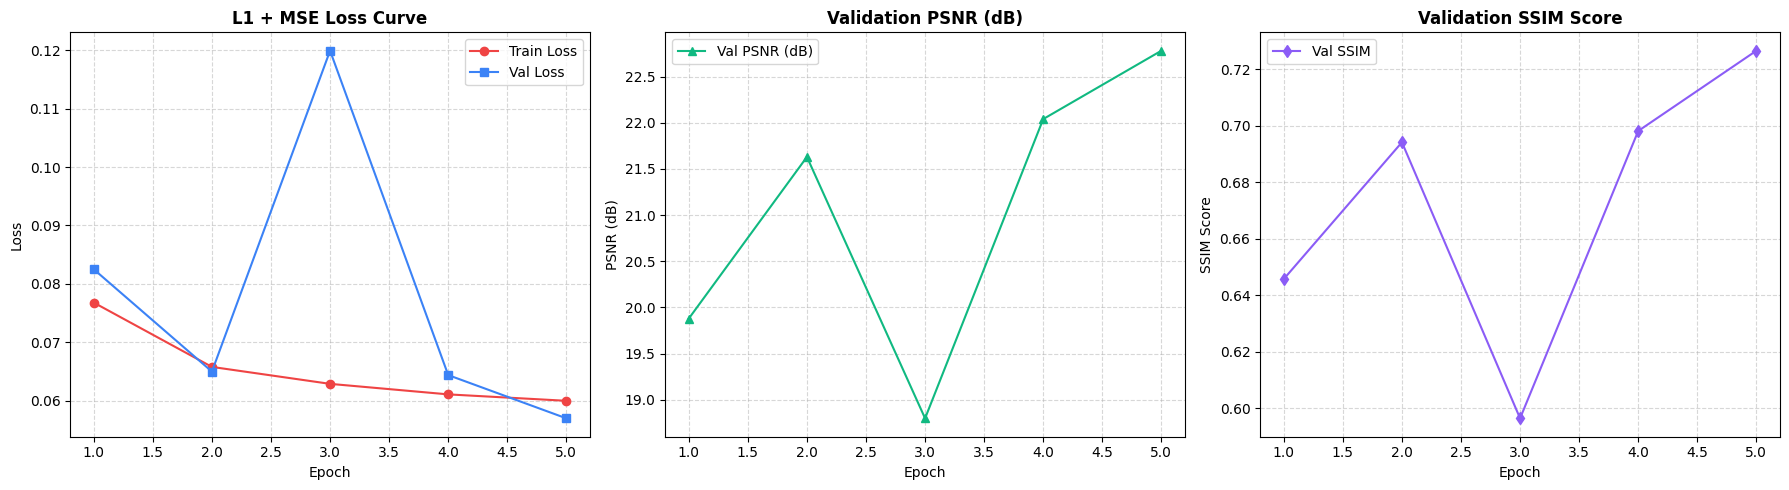

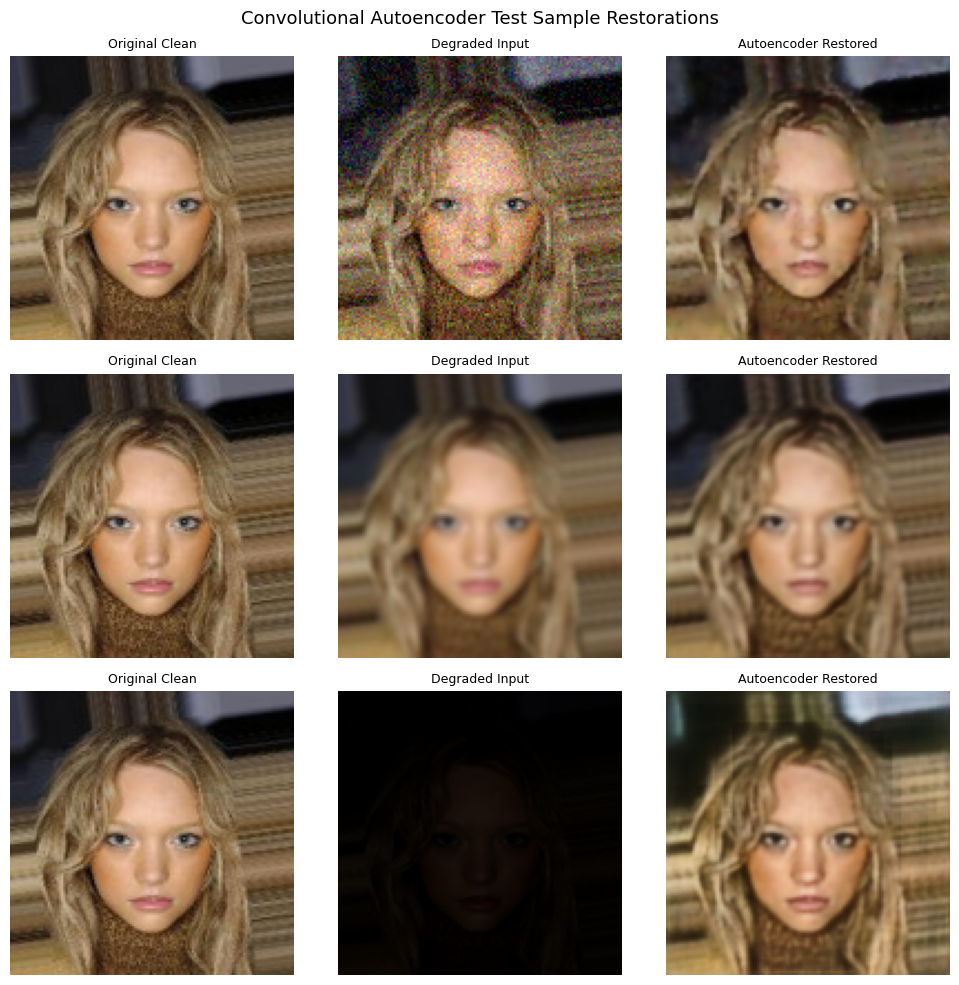

[Cell Timer - Plots and Visual Restorations] Cell Time: 4.25s | Cumulative Time: 3767.24s


In [8]:
_cell_start = time.time()

# Plot Training Curves and Generate Sample Visual Restorations
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Loss Curve
axes[0].plot(range(1, EPOCHS + 1), history["train_loss"], label="Train Loss", marker="o", color="#ef4444")
axes[0].plot(range(1, EPOCHS + 1), history["val_loss"], label="Val Loss", marker="s", color="#3b82f6")
axes[0].set_title("L1 + MSE Loss Curve", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend()

# PSNR Curve
axes[1].plot(range(1, EPOCHS + 1), history["val_psnr"], label="Val PSNR (dB)", marker="^", color="#10b981")
axes[1].set_title("Validation PSNR (dB)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("PSNR (dB)")
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend()

# SSIM Curve
axes[2].plot(range(1, EPOCHS + 1), history["val_ssim"], label="Val SSIM", marker="d", color="#8b5cf6")
axes[2].set_title("Validation SSIM Score", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("SSIM Score")
axes[2].grid(True, linestyle="--", alpha=0.5)
axes[2].legend()

plt.tight_layout()
plots_image_path = os.path.join(OUTPUT_DIR, "loss_psnr_ssim_curves.png")
plt.savefig(plots_image_path, dpi=300)
plt.show()

# Visual Restoration Samples Plot
model.eval()
for deg_b, clean_b in test_loader:
    deg_b, clean_b = deg_b.to(DEVICE), clean_b.to(DEVICE)
    with torch.no_grad():
        res_b = model(deg_b)
    break

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for i in range(min(3, deg_b.shape[0])):
    deg_np = deg_b[i].cpu().permute(1, 2, 0).numpy()
    res_np = res_b[i].cpu().permute(1, 2, 0).numpy()
    clean_np = clean_b[i].cpu().permute(1, 2, 0).numpy()
    
    axes[i, 0].imshow(clean_np)
    axes[i, 0].set_title("Original Clean", fontsize=9)
    axes[i, 0].axis("off")
    
    axes[i, 1].imshow(deg_np)
    axes[i, 1].set_title("Degraded Input", fontsize=9)
    axes[i, 1].axis("off")
    
    axes[i, 2].imshow(res_np)
    axes[i, 2].set_title("Autoencoder Restored", fontsize=9)
    axes[i, 2].axis("off")

plt.suptitle("Convolutional Autoencoder Test Sample Restorations", fontsize=13)
plt.tight_layout()
samples_image_path = os.path.join(OUTPUT_DIR, "test_restoration_samples.png")
plt.savefig(samples_image_path, dpi=300)
plt.show()

print_timer("Plots and Visual Restorations", _cell_start)

In [9]:
_cell_start = time.time()

# Package Checkpoints, Metrics, Plots into autoencoder_restoration_results.zip
ZIP_FILE_PATH = os.path.join(OUTPUT_DIR, "autoencoder_restoration_results.zip")

files_to_zip = [
    (MODEL_SAVE_PATH, "autoencoder_model.pth"),
    (metrics_json_path, "training_metrics.json"),
    (plots_image_path, "loss_psnr_ssim_curves.png"),
    (samples_image_path, "test_restoration_samples.png")
]

with zipfile.ZipFile(ZIP_FILE_PATH, "w", zipfile.ZIP_DEFLATED) as zipf:
    for src_path, arcname in files_to_zip:
        if os.path.exists(src_path):
            zipf.write(src_path, arcname=arcname)
            print(f"Added to Zip: {arcname}")

print(f"\n======================================================")
print(f"RESULTS ZIP ARCHIVE CREATED SUCCESSFULLY")
print(f"Zip Path: {ZIP_FILE_PATH}")
print(f"Size: {os.path.getsize(ZIP_FILE_PATH) / (1024 * 1024):.2f} MB")
print(f"Contains: autoencoder_model.pth, training_metrics.json, curves, visual samples")
print(f"======================================================")

print_timer("Zip Packaging and Export", _cell_start)

Added to Zip: autoencoder_model.pth
Added to Zip: training_metrics.json
Added to Zip: loss_psnr_ssim_curves.png
Added to Zip: test_restoration_samples.png

RESULTS ZIP ARCHIVE CREATED SUCCESSFULLY
Zip Path: /kaggle/working/autoencoder_restoration_results.zip
Size: 7.44 MB
Contains: autoencoder_model.pth, training_metrics.json, curves, visual samples
[Cell Timer - Zip Packaging and Export] Cell Time: 0.41s | Cumulative Time: 3769.30s
